In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/lamyalbert/volve-production-data/Volve production data.xlsx


In [2]:
import pandas as pd
df = pd.read_excel("/kaggle/input/datasets/lamyalbert/volve-production-data/Volve production data.xlsx")  # use the path Kaggle shows
df.shape
df.head()

,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,NPD_FACILITY_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,...,AVG_CHOKE_UOM,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE
0,2014-04-07,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,0.00000,...,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,WI
1,2014-04-08,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,OP
2,2014-04-09,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,OP
3,2014-04-10,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,OP
4,2014-04-11,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,310.37614,...,%,33.09788,10.47992,33.07195,0.0,0.0,0.0,NaN,production,OP


In [1]:
import pandas as pd
df = pd.read_excel("/kaggle/input/datasets/lamyalbert/volve-production-data/Volve production data.xlsx")  # use the path Kaggle shows
df.shape

(15634, 24)

In [5]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("/kaggle/input/datasets/lamyalbert/volve-production-data/Volve production data.xlsx")   

WELL, DATE = "WELL_BORE_CODE", "DATEPRD"
OIL, GAS, WAT = "BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL"

df[DATE] = pd.to_datetime(df[DATE])
df = df.sort_values([WELL, DATE]).reset_index(drop=True)

print(df.shape)
print(df[WELL].nunique(), "wells")
print(df[DATE].min(), "to", df[DATE].max())

(15634, 24)
7 wells
2007-09-01 00:00:00 to 2016-12-01 00:00:00


In [6]:
df = df.dropna(subset=[OIL])          # remove rows with no oil value
df = df[df[OIL] > 0].copy()           # keep only days the well produced oil

df["WATER_CUT"] = df[WAT] / (df[WAT] + df[OIL])
df["CUM_OIL"] = df.groupby(WELL)[OIL].cumsum()
df.shape

(8008, 26)

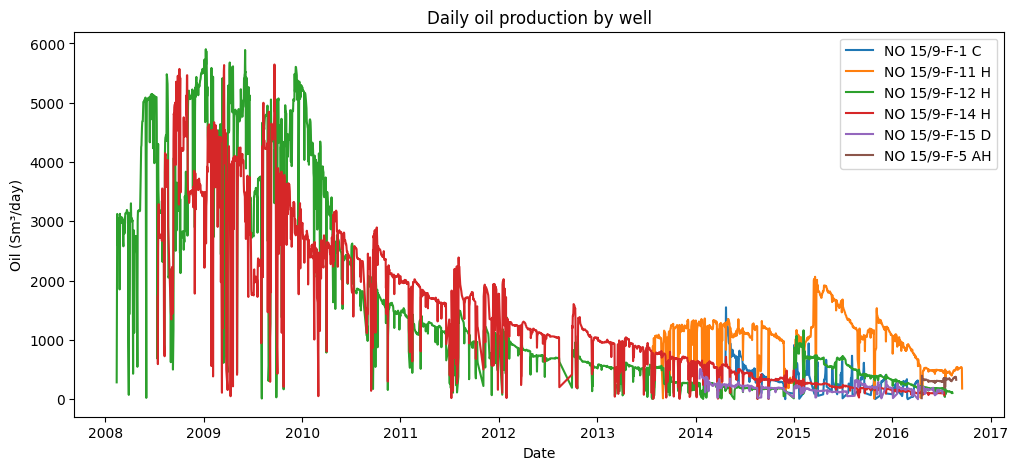

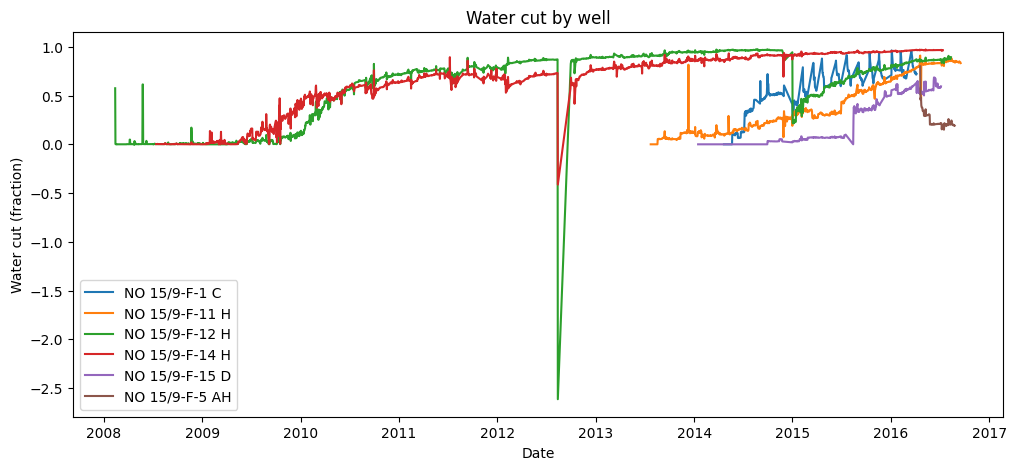

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))
for well, g in df.groupby(WELL):
    ax.plot(g[DATE], g[OIL], label=well)
ax.set_title("Daily oil production by well")
ax.set_xlabel("Date"); ax.set_ylabel("Oil (Sm³/day)")
ax.legend();
plt.savefig("oil_by_well.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
for well, g in df.groupby(WELL):
    ax.plot(g[DATE], g["WATER_CUT"], label=well)
ax.set_title("Water cut by well")
ax.set_xlabel("Date"); ax.set_ylabel("Water cut (fraction)")
ax.legend();
plt.savefig("water_cut_by_well.png", dpi=150, bbox_inches="tight") 
plt.show()

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

g = df.groupby(WELL)[OIL]
df["TARGET"] = g.shift(-1)                      # tomorrow's oil
df["OIL_LAG1"] = df[OIL]                        # today's oil
df["OIL_MEAN7"] = g.transform(lambda s: s.rolling(7, min_periods=1).mean())

candidates = ["OIL_LAG1", "OIL_MEAN7", "WATER_CUT", "ON_STREAM_HRS",
              "AVG_DOWNHOLE_PRESSURE", "AVG_WHP_P", "AVG_CHOKE_SIZE_P"]
features = [c for c in candidates if c in df.columns]
print("Using features:", features)

data = df.dropna(subset=features + ["TARGET"]).copy()

# Time-based split: train on the earlier 80% of dates, test on the later 20%
cut = data[DATE].quantile(0.8)
train, test = data[data[DATE] <= cut], data[data[DATE] > cut]

baseline_pred = test["OIL_LAG1"]
print("Baseline MAE:", round(mean_absolute_error(test["TARGET"], baseline_pred), 2))

model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
model.fit(train[features], train["TARGET"])
pred = model.predict(test[features])

print("Model MAE:   ", round(mean_absolute_error(test["TARGET"], pred), 2))
print("Model R2:    ", round(r2_score(test["TARGET"], pred), 3))

Using features: ['OIL_LAG1', 'OIL_MEAN7', 'WATER_CUT', 'ON_STREAM_HRS', 'AVG_DOWNHOLE_PRESSURE', 'AVG_WHP_P', 'AVG_CHOKE_SIZE_P']
Baseline MAE: 20.96
Model MAE:    60.15
Model R2:     0.926


In [9]:
# New features: day-to-day changes
df["OIL_DIFF1"] = df.groupby(WELL)[OIL].diff()
for c in ["AVG_DOWNHOLE_PRESSURE", "AVG_WHP_P", "AVG_CHOKE_SIZE_P"]:
    if c in df.columns:
        df[c + "_DIFF"] = df.groupby(WELL)[c].diff()

# Target = change from today to tomorrow
df["DELTA"] = df["TARGET"] - df["OIL_LAG1"]

feat2 = ["OIL_LAG1", "OIL_DIFF1", "OIL_MEAN7", "WATER_CUT", "ON_STREAM_HRS"] + \
        [c for c in df.columns if c.endswith("_DIFF") and c != "OIL_DIFF1"]
feat2 = [c for c in feat2 if c in df.columns]
print("Using:", feat2)

data2 = df.dropna(subset=feat2 + ["DELTA"]).copy()
cut = data2[DATE].quantile(0.8)
train2, test2 = data2[data2[DATE] <= cut], data2[data2[DATE] > cut]

m2 = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
m2.fit(train2[feat2], train2["DELTA"])
pred2 = test2["OIL_LAG1"] + m2.predict(test2[feat2])      # today + predicted change

print("Baseline MAE:", round(mean_absolute_error(test2["TARGET"], test2["OIL_LAG1"]), 2))
print("Model MAE:   ", round(mean_absolute_error(test2["TARGET"], pred2), 2))
print("Baseline R2: ", round(r2_score(test2["TARGET"], test2["OIL_LAG1"]), 3))
print("Model R2:    ", round(r2_score(test2["TARGET"], pred2), 3))

Using: ['OIL_LAG1', 'OIL_DIFF1', 'OIL_MEAN7', 'WATER_CUT', 'ON_STREAM_HRS', 'AVG_DOWNHOLE_PRESSURE_DIFF', 'AVG_WHP_P_DIFF', 'AVG_CHOKE_SIZE_P_DIFF']
Baseline MAE: 21.01
Model MAE:    25.72
Baseline R2:  0.963
Model R2:     0.961


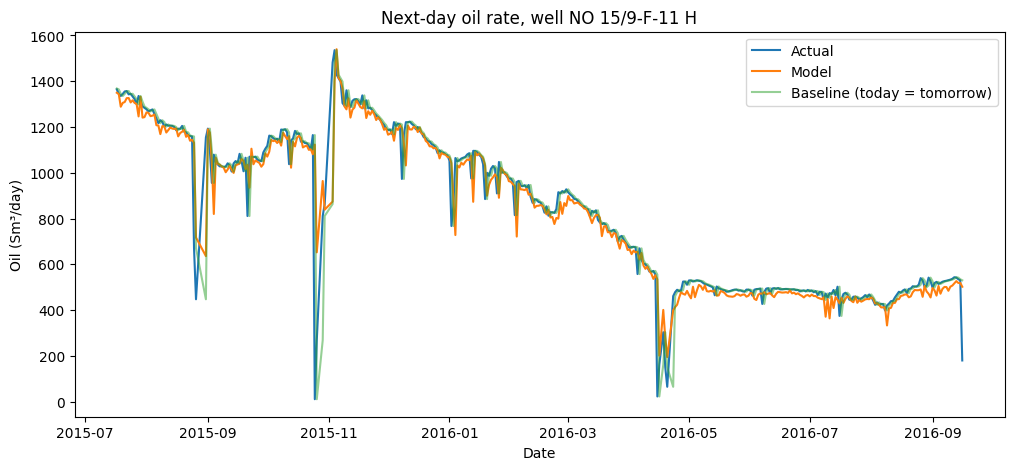

In [14]:
test2 = test2.assign(PRED=pred2)
well = test2[WELL].value_counts().index[0]          # well with most test days
t = test2[test2[WELL] == well]
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t[DATE], t["TARGET"], label="Actual")
ax.plot(t[DATE], t["PRED"], label="Model")
ax.plot(t[DATE], t["OIL_LAG1"], label="Baseline (today = tomorrow)", alpha=0.5)
ax.set_title(f"Next-day oil rate, well {well}")
ax.set_xlabel("Date"); ax.set_ylabel("Oil (Sm³/day)"); ax.legend();
plt.savefig("actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def evaluate(name, model, horizon):
    d = df.copy()
    d["TARGET_H"] = d.groupby(WELL)[OIL].shift(-horizon)
    d["DELTA_H"] = d["TARGET_H"] - d["OIL_LAG1"]
    dd = d.dropna(subset=feat2 + ["DELTA_H"])
    cut = dd[DATE].quantile(0.8)
    tr, te = dd[dd[DATE] <= cut], dd[dd[DATE] > cut]
    model.fit(tr[feat2], tr["DELTA_H"])
    p = te["OIL_LAG1"] + model.predict(te[feat2])
    return {"model": name, "horizon_days": horizon,
            "baseline_MAE": round(mean_absolute_error(te["TARGET_H"], te["OIL_LAG1"]), 2),
            "model_MAE": round(mean_absolute_error(te["TARGET_H"], p), 2)}

models = {
    "Ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "GradientBoosting (MAE loss)": lambda: HistGradientBoostingRegressor(loss="absolute_error", random_state=42),
    "RandomForest": lambda: RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1),
}
rows = [evaluate(n, f(), h) for h in (1, 7) for n, f in models.items()]
results = pd.DataFrame(rows)
results["improvement_%"] = ((results["baseline_MAE"] - results["model_MAE"]) / results["baseline_MAE"] * 100).round(1)
results

,model,horizon_days,baseline_MAE,model_MAE,improvement_%
0,Ridge,1,21.01,40.80,-94.2
1,GradientBoosting (MAE loss),1,21.01,21.19,-0.9
2,RandomForest,1,21.01,25.72,-22.4
3,Ridge,7,47.07,64.89,-37.9
4,GradientBoosting (MAE loss),7,47.07,43.60,7.4
5,RandomForest,7,47.07,60.61,-28.8
